# Classical, neoclassical and turbulent transport of one plasma state

How much heat would each transport mechanism carry in VEST shot 48224 at 300 ms,
and where along the radius does each one apply?

One resolved kinetic state is handed to four models. Each answer is written to the
same `core_transport` IDS, and all four are drawn on one $\rho_{tor,N}$ axis:

| family | model | how it is evaluated | `core_transport.model[].identifier.index` |
| --- | --- | --- | --- |
| classical | Braginskii perpendicular conduction | closed form, every surface | -1 (VAFT private: the data dictionary has no classical entry) |
| neoclassical | Chang-Hinton ion conduction | closed form, every surface | 5 `neoclassical` |
| neoclassical | NEO drift-kinetic solution | solver, 7 surfaces | 5 `neoclassical` |
| turbulent | TGLF quasilinear, SAT3 electromagnetic | solver, 5 surfaces | 6 `anomalous` |

Three kinds of number are kept apart throughout:

| | |
| --- | --- |
| **Measured** | electron density and temperature (Thomson), ion temperature (CES), the kinetic EFIT + CHEASE equilibrium |
| **Modelling assumption** | $Z_\mathrm{eff} = 2$ carried by fully stripped carbon, the profile truncation at $\rho = 0.95$ |
| **Computed** | every flux on this page, each under its own model's assumptions |

**Energy flux $Q$, not diffusivity $\chi$.** Every model here produces $Q$ directly.
$\chi = Q / (n\,\partial T/\partial r)$ would have to be derived, and on this state
both $\partial T_e/\partial r$ and $\partial T_i/\partial r$ change sign inside the
plasma (section 2). At those radii $\chi$ is $0/0$, so a $\chi$ plot would show
spikes that come from the profile, not from any model. $Q$ stays finite there and
keeps its sign. The figure therefore uses a symmetric-log axis: logarithmic in
magnitude and linear through zero.

Reading order is top to bottom. Section 1 resolves the state; section 2 evaluates
the closed forms; sections 3 and 4 run NEO and TGLF; section 5 draws the overlay;
section 6 reads it off; section 7 says what it does and does not establish.

**Companion notebooks.** `neoclassical_transport_with_neo.ipynb` compares the
bootstrap current with Sauter and Redl, and `turbulent_transport_with_tglf.ipynb`
audits the TGLF-NN surrogate. Both use this same state.

## 0. Setup

NEO and TGLF are external GACODE executables. They are found through
`$GACODEHOME/{neo,tglf}/bin` and `$GACODE_PLATFORM`. Without them, sections 3 and 4
report what they would show and skip. The closed forms are pure VAFT and always run.

In [ ]:
import contextlib
import importlib.util
import os
import tempfile
from pathlib import Path

try:
    _ipython = get_ipython()
except NameError:
    _ipython = None
if _ipython is None:
    os.environ.setdefault("MPLBACKEND", "Agg")
elif "IPKernelApp" in _ipython.config:
    _ipython.run_line_magic("matplotlib", "inline")

import matplotlib.pyplot as plt
import numpy as np
from omas import load_omas_json

import vaft
import vaft.omas
from vaft.code.gacode import find_gacode_executable, neo, tglf
from vaft.code.gacode.tglf import surrogate
from vaft.process.transport_state import (
    TransportStateKey,
    assess_neo_readiness,
    assess_tglf_readiness,
    chang_hinton_heat_flux,
    classical_heat_fluxes,
    resolve_transport_state,
    surface_toroidal_field,
)

plt.rcParams["figure.dpi"] = 110

# Modelling assumptions, named here rather than buried in a call below.
#
# Z_EFF / IMPURITY: the packaged state carries no Z_eff profile. 2.0 is the value the
#   rest of VAFT's ohmic and transport estimates use, and naming carbon makes the
#   solvers see it: n_H = 0.8 n_e, n_C = n_e/30. Every model below gets this same
#   species list, which is the reason the state is resolved once.
# RHO_MAX: the fitted profiles reach zero at the boundary, and GACODE takes
#   logarithmic gradients, so the profile stops short of it.
Z_EFF = 2.0
IMPURITY = "C"
RHO_MAX = 0.95
SAT_RULE = 3

# Where each model is evaluated, as r/a. The closed forms are cheap and are drawn as
# lines, so they get a fine grid. The solvers are drawn only at the surfaces they
# solved; these are the surfaces the two companion notebooks use.
DENSE = tuple(np.round(np.arange(0.10, 0.901, 0.025), 3))
NEO_BAND = (0.2, 0.8, 7)          # RMIN_OVER_A, RMIN_OVER_A_2, N_RADIAL
TGLF_RADII = (0.2, 0.35, 0.5, 0.65, 0.8)
SURROGATE_FAMILY = "sat3_em_d3d+mastu+nstx_azf-1"

SAMPLE = vaft.data.data_path("kineticEfit/ods_48224_300ms.json")
_repo_root = Path(vaft.__file__).resolve().parents[1]
OUTPUT_DIR = Path(os.environ.get("VAFT_NOTEBOOK_OUTPUT_DIR",
                                 _repo_root / "notebooks" / "outputs" / "transport_hierarchy"))
NEO_CONFIG = neo.NEOConfig(n_radial=NEO_BAND[2], rmin_over_a=NEO_BAND[0],
                           rmin_over_a_2=NEO_BAND[1], platform=os.environ.get("GACODE_PLATFORM"))
TGLF_CONFIG = tglf.TGLFConfig(sat_rule=SAT_RULE, use_bper=True,
                              platform=os.environ.get("GACODE_PLATFORM"))

# find_gacode_executable returns None when nothing is configured, and raises when
# $GACODEHOME is set but the tree is not built.
EXECUTABLES = {}
for name, config in (("neo", NEO_CONFIG), ("tglf", TGLF_CONFIG)):
    try:
        EXECUTABLES[name] = find_gacode_executable(config, name)
    except (FileNotFoundError, PermissionError) as error:
        print(f"GACODE is configured but {name.upper()} is not usable:\n  {error}\n")
        EXECUTABLES[name] = None
HAVE_NEO = EXECUTABLES["neo"] is not None
HAVE_TGLF = EXECUTABLES["tglf"] is not None
HAVE_GACODE = HAVE_NEO or HAVE_TGLF

print(f"sample       {SAMPLE.name}  ({'present' if SAMPLE.exists() else 'MISSING'})")
print(f"assumptions  Z_eff = {Z_EFF} as {IMPURITY}, rho_max = {RHO_MAX}")
print(f"NEO          {'found' if HAVE_NEO else 'not found'}")
print(f"TGLF         {'found' if HAVE_TGLF else 'not found'}  (SAT{SAT_RULE}, electromagnetic)")
if not HAVE_GACODE:
    print("\nGACODE was not found. Set $GACODEHOME to a built checkout and $GACODE_PLATFORM"
          "\nto its build tag. Sections 3 and 4 report what they would show and skip;"
          "\nthe overlay then carries the two closed forms only.")

sample       ods_48224_300ms.json  (present)
assumptions  Z_eff = 2.0 as C, rho_max = 0.95
NEO          found
TGLF         found  (SAT3, electromagnetic)


## 1. One state

`resolve_transport_state` builds the GACODE profile that every model reads. It records,
per quantity, whether the value was measured, reconstructed, derived or assumed. The
state's identity is a hash of everything a solver is given, and it is written into
every `core_transport` entry below. Rows from two different states therefore cannot be
mixed.

In [ ]:
ods = load_omas_json(str(SAMPLE), consistency_check=False)
TIME = float(np.ravel(ods["equilibrium.time"])[0])
KEY = TransportStateKey(48224, TIME, "electron_kinetic")
STATE = resolve_transport_state(
    ods, KEY, efit_quality="good", quality_source="packaged kinetic sample",
    z_eff=Z_EFF, impurity=IMPURITY, rho_max=RHO_MAX,
)
assert STATE.resolved, STATE.reasons

print(f"state        {KEY.slug()}  ({STATE.status})")
print(f"identity     {STATE.identity[:16]}...")
print(f"species      {STATE.composition['species']}  Z_eff = {STATE.composition['z_eff']}"
      f"  ({STATE.composition['origin']})")
print(f"T_i          {STATE.ti_lineage}")
print()
for quantity in ("ne", "te", "ti", "ni", "equilibrium", "q"):
    record = STATE.provenance.get(quantity, {})
    print(f"  {quantity:12s} {record.get('kind', '-'):20s} {record.get('source', record.get('method', ''))}")

state        48224/electron_kinetic/00300  (resolved)
identity     bb76a8a6f32cf2ad...
species      ['H+', 'C6+']  Z_eff = 2.0  (policy_assumption)
T_i          measured

  ne           measured             core_profiles.profiles_1d.0.electrons
  te           measured             core_profiles.profiles_1d.0.electrons
  ti           measured             core_profiles ion temperature
  ni           policy_assumption    core_profiles.profiles_1d.0.electrons.density_thermal
  equilibrium  reconstructed        
  q            reconstructed        equilibrium


## 2. The closed forms: classical and Chang-Hinton

Both closed forms are evaluated from the same TGLF local input at every surface. That
input is what TGLF itself reads, so the gradients, $q$, the geometry and the species
fractions are identical to the solver's.

* **Classical** (`classical_heat_fluxes`): Braginskii perpendicular conduction in the
  strongly magnetised limit, $q_{\perp s} = -\kappa_{\perp s}\,\partial T_s/\partial r$
  with $\kappa_\perp \propto nT/(m\Omega^2\tau)$. It covers electrons and the main ion
  and gives no particle flux.
* **Neoclassical, closed form** (`chang_hinton_heat_flux`): Chang and Hinton's
  main-ion conduction with the $Z_\mathrm{eff}$ correction. It reproduces NEO's own
  `compute_CH` to NEO's rounding (`test_formula_neoclassical.py`). Sauter and Redl
  carry no heat flux, and there is no closed form here for the electron neoclassical
  heat flux.

Does NEO already report a classical component separately? It does not. NEO writes
its drift-kinetic flux (`out.neo.transport`) and, beside it, a gyroviscous flux
(`out.neo.transport_gv`). The gyroviscous flux is a rotation-driven correction, not
Braginskii's collisional flux, and section 3 shows it is identically zero for this
non-rotating run. NEO's output has no Braginskii channel, so the classical curve comes
from the formula.

In [ ]:
DENSE_READINESS = assess_tglf_readiness(STATE, DENSE, config=TGLF_CONFIG)
LOCALS = {s.r_over_a: s.local_input for s in DENSE_READINESS.surfaces if s.ready}
CLASSICAL = [classical_heat_fluxes(local, surface_toroidal_field(STATE.profile, local))
             for local in LOCALS.values()]
CHANG_HINTON = [chang_hinton_heat_flux(local) for local in LOCALS.values()]
print(f"{len(LOCALS)} of {len(DENSE)} surfaces ready; "
      f"not ready: {[s.r_over_a for s in DENSE_READINESS.surfaces if not s.ready] or 'none'}")

print(f"\n  {'r/a':>5s} {'a/L_Te':>8s} {'a/L_Ti':>8s} {'nu*_i':>7s}"
      f" {'Q_e classical':>14s} {'Q_i classical':>14s} {'Q_i Chang-Hinton':>17s}  [W/m^2]")
for (r, local), cl, ch in zip(LOCALS.items(), CLASSICAL, CHANG_HINTON):
    if round(r / 0.1, 6) % 1:   # print every 0.1 in r/a
        continue
    print(f"  {r:5.2f} {local.rlts[0]:8.2f} {local.rlts[1]:8.2f} {ch['nu_star_i']:7.1f}"
          f" {cl.electron_energy_flux_W_m2:14.3g} {next(iter(cl.ion_energy_flux_W_m2.values())):14.3g}"
          f" {next(iter(ch['ion_energy_flux_W_m2'].values())):17.3g}")
print("\nA negative a/L_T is a temperature rising outward; the conductive flux follows it"
      "\ninward. nu*_i >> 1 to r/a = 0.7 (Pfirsch-Schlueter); towards the edge it falls"
      "\nto the plateau boundary, nu*_i ~ epsilon^-3/2 in this normalisation.")

33 of 33 surfaces ready; not ready: none

    r/a   a/L_Te   a/L_Ti   nu*_i  Q_e classical  Q_i classical  Q_i Chang-Hinton  [W/m^2]
   0.10    -0.72     0.59   129.8          -29.2            118               129
   0.20    -1.21     1.21    51.5            -46            201               230
   0.30    -1.28     1.48    33.4          -42.1            182               180
   0.40    -1.01     1.20    25.0          -25.7           97.5              73.4
   0.50    -0.44     0.26    17.2          -7.52           12.9             -22.6
   0.60     0.37    -0.64     9.7           3.43          -17.6             -56.3
   0.70     1.51    -0.61     4.8           5.73          -7.61             -33.4
   0.80     3.29     0.79     2.5           3.41           3.09             -1.34
   0.90     6.93     4.55     1.8          0.965           2.72              6.32

A negative a/L_T is a temperature rising outward; the conductive flux follows it
inward. nu*_i >> 1 to r/a = 0.7 (Pfirsch-Schlue

In [ ]:
from vaft.machine_mapping.classical import core_transport_from_classical
from vaft.machine_mapping.neoclassical import core_transport_from_chang_hinton

REPORTS = {}
REPORTS["classical"] = core_transport_from_classical(
    ods, CLASSICAL, STATE.profile, time=TIME, state_identity=STATE.identity,
    efit_lineage=KEY.efit_lineage)
REPORTS["chang_hinton"] = core_transport_from_chang_hinton(
    ods, CHANG_HINTON, STATE.profile, time=TIME, state_identity=STATE.identity)
for name, report in REPORTS.items():
    print(f"{name:13s} -> core_transport.model.{report['model']}: {', '.join(report['written'])}")
    for reason in report["skipped"]:
        print(f"{'':16s}not written: {reason}")

classical     -> core_transport.model.0: electrons.energy.flux, electrons.energy.d, ion.0.energy.flux, ion.0.energy.d
                not written: particles.flux (the model evaluates no particle flux: not evaluated, not zero)
                not written: impurity ions (the model covers electrons and the main ion only)
                not written: collision times, Coulomb logarithms, gamma_1', |B| (diagnostics with no core_transport home; they stay in the native record)
chang_hinton  -> core_transport.model.1: ion.0.energy.flux
                not written: electrons.energy.flux (no closed-form electron neoclassical heat flux is evaluated)
                not written: particles.flux (not evaluated, not zero)
                not written: impurity ions (the closed form covers the main ion only)


## 3. NEO

NEO solves the drift-kinetic equation for every species at the surfaces of the band.
Its particle and energy fluxes are SI totals: they include convection, and the ion flux
is per species. The run's own species list is checked against the state, because NEO
ignores the `z_eff` column and builds its collision operator from the species alone.

At the same surfaces, VAFT's Chang-Hinton is also compared with the Chang-Hinton value
that NEO prints beside its solution. This checks that the closed-form line and the NEO
markers in the overlay come from one plasma.

In [ ]:
_cleanup = contextlib.ExitStack()
RUN_DIR = None
NEO_RESULT = None
HAVE_NEO_RUN = False

if HAVE_NEO:
    RUN_DIR = Path(_cleanup.enter_context(tempfile.TemporaryDirectory(prefix="vaft-hierarchy-")))
    readiness = assess_neo_readiness(STATE, NEO_BAND[:2])
    if readiness.runnable:
        NEO_RESULT = neo.run_neo_case(STATE.profile, RUN_DIR / "neo", NEO_CONFIG, check=False)
        HAVE_NEO_RUN = NEO_RESULT.ok
    else:
        print("the state is not ready for NEO:", readiness.reasons)

if HAVE_NEO_RUN:
    from vaft.machine_mapping.neoclassical import core_transport_from_neo

    native = NEO_RESULT.outputs_native
    REPORTS["neo"] = core_transport_from_neo(ods, NEO_RESULT, time=TIME, time_index=0)
    print(f"revision        {native.version['revision']}")
    print(f"surfaces        r/a = {np.round(native.grid.r_over_a, 3)}")
    print(f"Z_eff NEO used  {float(np.nanmean(native.effective_charge)):.3f}"
          f"  ({native.n_species} species)")
    print(f"files written   {', '.join(sorted(native.files))}")
    gv = native.transport_gyroviscous
    if gv is not None:
        ratio = np.max(np.abs(gv["energy_flux"])) / np.max(np.abs(native.transport["energy_flux"]))
        print(f"gyroviscous     max |Q_gv| / max |Q_dke| = {ratio:.3g}"
              f"  (ROTATION_MODEL = {NEO_CONFIG.rotation_model},"
              f" omega_0 = {np.max(np.abs(native.equilibrium['omega0'])):g}: no rotation was given)")
    else:
        print("gyroviscous     not written")
    print("                neither is a classical (Braginskii) flux; NEO has no such channel")
    print(f"-> core_transport.model.{REPORTS['neo']['model']}: {', '.join(REPORTS['neo']['written'])}")
elif NEO_RESULT is not None:
    print(f"NEO did not produce a usable result (rc={NEO_RESULT.returncode}).")
    for line in getattr(NEO_RESULT.outputs_native, "errors", ()) or ():
        print(f"  {line}")
else:
    print("Would run NEO at seven surfaces between r/a = 0.2 and 0.8, map its electron"
          "\nand per-ion energy fluxes into core_transport, and check VAFT's Chang-Hinton"
          "\nagainst the value NEO prints at the same surfaces.")

revision        6357db30 [2026-07-22]
surfaces        r/a = [0.2 0.3 0.4 0.5 0.6 0.7 0.8]
Z_eff NEO used  2.000  (3 species)
files written   out.neo.diagnostic_geo, out.neo.diagnostic_geo2, out.neo.equil, out.neo.expnorm, out.neo.exprhon, out.neo.f, out.neo.grid, out.neo.gxi, out.neo.gxi_t, out.neo.gxi_x, out.neo.phi, out.neo.prec, out.neo.run, out.neo.species, out.neo.theory, out.neo.transport, out.neo.transport_exp, out.neo.transport_flux, out.neo.transport_gv, out.neo.vel, out.neo.vel_fourier, out.neo.version
gyroviscous     max |Q_gv| / max |Q_dke| = 0  (ROTATION_MODEL = 1, omega_0 = 0: no rotation was given)
                neither is a classical (Braginskii) flux; NEO has no such channel
-> core_transport.model.2: electrons.particles.flux, electrons.energy.flux, ion.0.particles.flux, ion.0.energy.flux, ion.1.particles.flux, ion.1.energy.flux


In [ ]:
if HAVE_NEO_RUN:
    from scipy import constants

    native = NEO_RESULT.outputs_native
    norm = native.normalisation
    # NEO's energy unit, from its own out.neo.expnorm: n_0 T_0 v_0.
    scale = norm.density_norm * 1e19 * norm.temperature_norm * 1e3 * constants.e * norm.velocity_norm_times_a
    neo_ch = np.asarray(native.theory["chang_hinton_ion_energy_flux"]) * scale
    surfaces = assess_tglf_readiness(STATE, tuple(np.round(native.grid.r_over_a, 4)), config=TGLF_CONFIG)
    vaft_ch = np.array([next(iter(chang_hinton_heat_flux(s.local_input)["ion_energy_flux_W_m2"].values()))
                        for s in surfaces.surfaces])
    print(f"  {'r/a':>5s} {'VAFT Chang-Hinton':>18s} {'NEO compute_CH':>15s} {'ratio':>8s}  [W/m^2]")
    for r, ours, theirs in zip(native.grid.r_over_a, vaft_ch, neo_ch):
        print(f"  {r:5.2f} {ours:18.4g} {theirs:15.4g} {ours / theirs:8.5f}")
else:
    print("Would print VAFT's Chang-Hinton beside NEO's own compute_CH at the NEO surfaces.")

    r/a  VAFT Chang-Hinton  NEO compute_CH    ratio  [W/m^2]
   0.20                230           230.1  0.99976
   0.30              179.9           179.9  0.99965
   0.40              73.43           73.45  0.99971
   0.50             -22.56          -22.58  0.99918
   0.60             -56.31          -56.34  0.99944
   0.70             -33.45          -33.47  0.99942
   0.80             -1.337          -1.341  0.99723


## 4. TGLF

TGLF runs at five surfaces with SAT3 and the perpendicular magnetic perturbation.
These match the turbulent-transport notebook. Its gyro-Bohm fluxes are made
dimensional with each surface's own gyro-Bohm unit and re-indexed from $r/a$ onto
$\rho_{tor,N}$ when they are mapped.

The **TGLF-NN surrogate is not drawn.** On this state every public family is outside
its training domain. The decisive input is $T_i/T_e$: VEST's ions are several times
colder than the electrons, and no training set covers that. The default path refuses
the surrogate. An extrapolated number would look like a result without being one, so
the figure carries a one-line note instead of a curve.

In [ ]:
TGLF_RESULTS = {}
if HAVE_TGLF:
    if RUN_DIR is None:
        RUN_DIR = Path(_cleanup.enter_context(tempfile.TemporaryDirectory(prefix="vaft-hierarchy-")))
    TGLF_READINESS = assess_tglf_readiness(STATE, TGLF_RADII, config=TGLF_CONFIG)
    for surface in TGLF_READINESS.surfaces:
        if surface.ready:
            TGLF_RESULTS[surface.r_over_a] = (surface.local_input, tglf.run_tglf_case(
                STATE.profile, surface.r_over_a, RUN_DIR / f"tglf_r{surface.r_over_a:.2f}",
                TGLF_CONFIG, check=False))
HAVE_TGLF_RUN = any(result.ok for _, result in TGLF_RESULTS.values())

if HAVE_TGLF_RUN:
    from vaft.machine_mapping.turbulence import core_transport_from_tglf

    REPORTS["tglf"] = core_transport_from_tglf(
        ods, list(TGLF_RESULTS.values()), STATE.profile, time=TIME, state_identity=STATE.identity)
    first = next(result.outputs_native for _, result in TGLF_RESULTS.values() if result.ok)
    print(f"revision        {first.version['revision']}")
    print(f"solved          r/a = {[r for r, (_, res) in TGLF_RESULTS.items() if res.ok]}"
          f" of {list(TGLF_RADII)}")
    print(f"-> core_transport.model.{REPORTS['tglf']['model']}: {', '.join(REPORTS['tglf']['written'])}")
else:
    print("Would run TGLF at five surfaces and map its dimensional electron and per-ion"
          "\nenergy fluxes into core_transport as an anomalous (index 6) model.")

# The surrogate's verdict, computed rather than quoted, when the models resolve.
SURROGATE_NOTE = "TGLF-NN surrogate: not qualified for this state (outside training domain), not drawn"
try:
    MODELS = surrogate.available_models()
except Exception:  # noqa: BLE001 - an unreadable model store is "no models", not a crash
    MODELS = {}
if SURROGATE_FAMILY in MODELS:
    identity = surrogate.resolve_model(SURROGATE_FAMILY)
    audit = surrogate.audit_training_domain(
        assess_tglf_readiness(STATE, (0.5,), config=TGLF_CONFIG).surfaces[0].local_input,
        identity, surrogate.load_metadata(identity), config=TGLF_CONFIG, threshold=3.0)
    print(f"\n{SURROGATE_FAMILY} at r/a = 0.5: {audit.summary()}")
    if not audit.in_domain:
        worst = audit.violations[0]
        SURROGATE_NOTE = (f"TGLF-NN surrogate not qualified: {worst} z = "
                          f"{audit.z_scores[worst]:+.1f} at r/a = 0.5; not drawn")
print(f"\nfigure note: {SURROGATE_NOTE}")

revision        6357db30 [2026-07-22]
solved          r/a = [0.2, 0.35, 0.5, 0.65, 0.8] of [0.2, 0.35, 0.5, 0.65, 0.8]
-> core_transport.model.3: electrons.particles.flux, electrons.energy.flux, ion.0.particles.flux, ion.0.energy.flux, ion.1.particles.flux, ion.1.energy.flux

sat3_em_d3d+mastu+nstx_azf-1 at r/a = 0.5: sat3_em_d3d+mastu+nstx_azf-1: 2 of 31 inputs beyond 3 sigma (TAUS_3 z=-4.5, TAUS_2 z=-4.4)

figure note: TGLF-NN surrogate not qualified: TAUS_3 z = -4.5 at r/a = 0.5; not drawn


## 5. The overlay

The figure is drawn by a registered plot recipe that reads only `core_transport`. It
builds one series per `model[]` entry and labels it by `identifier.index` and
`code.name`. Closed forms are drawn as lines; solver results are drawn as markers at
the surfaces actually solved, with no interpolation between them. Every model is
matched to the state's slice by its own time. Reloading the ODS from disk gives the
same figure: the overlay needs nothing that lives only in this session.

The ion panel is the **main ion (H$^+$)** for every model. Only the solvers carry the
carbon flux, so an ion total would compare different species content.

In [ ]:
import json

from omas import save_omas_json

with tempfile.TemporaryDirectory() as scratch:
    path = Path(scratch) / "ods_48224_transport_hierarchy.json"
    save_omas_json(ods, str(path))
    RELOADED = load_omas_json(str(path), consistency_check=False)

print("core_transport.model[] in the reloaded ODS:")
for m in range(len(RELOADED["core_transport.model"])):
    base = f"core_transport.model.{m}"
    rho = RELOADED[f"{base}.profiles_1d.0.grid_flux.rho_tor_norm"]
    print(f"  [{m}] identifier {RELOADED[f'{base}.identifier.index']:>2d}"
          f" {RELOADED[f'{base}.identifier.name']:13s} {str(RELOADED[f'{base}.code.name']):55s}"
          f" {len(rho):2d} surfaces, rho {rho.min():.2f}-{rho.max():.2f}")

core_transport.model[] in the reloaded ODS:
  [0] identifier -1 classical     vaft.process.transport_state.classical_heat_fluxes      33 surfaces, rho 0.09-0.82
  [1] identifier  5 neoclassical  vaft.process.transport_state.chang_hinton_heat_flux     33 surfaces, rho 0.09-0.82
  [2] identifier  5 neoclassical  NEO                                                      7 surfaces, rho 0.17-0.71
  [3] identifier  6 anomalous     TGLF                                                     5 surfaces, rho 0.17-0.71


saved: notebooks/outputs/transport_hierarchy/transport_hierarchy_48224_300ms.pdf, notebooks/outputs/transport_hierarchy/transport_hierarchy_48224_300ms.png


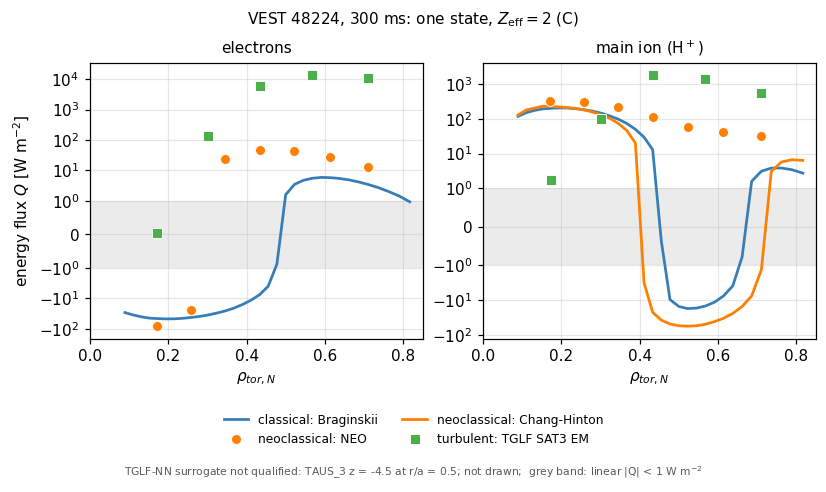

In [ ]:
LINTHRESH = 1.0   # W/m^2: linear (and signed) below, logarithmic above, in both panels

fig, axes = plt.subplots(1, 2, figsize=(7.4, 3.5), sharex=True, constrained_layout=True)
for ax, name, title in zip(
        axes,
        ("transport_hierarchy_profile_electron_energy_flux", "transport_hierarchy_profile_ion_energy_flux"),
        ("electrons", "main ion (H$^+$)")):
    vaft.omas.render_plot(name, RELOADED, ax=ax, legend=False)
    ax.set_yscale("symlog", linthresh=LINTHRESH)
    ax.set_title(title, fontsize=10)
    ax.set_ylabel(r"energy flux $Q$ [W m$^{-2}$]" if ax is axes[0] else "")
    ax.set_xlabel(r"$\rho_{tor,N}$")
    ax.set_xlim(0.0, 0.85)
    ax.axhspan(-LINTHRESH, LINTHRESH, color="0.92", zorder=0, linewidth=0)
handles, labels = {}, {}
for ax in axes:
    for handle, label in zip(*ax.get_legend_handles_labels()):
        handles.setdefault(label, handle)
order = sorted(handles, key=lambda label: [k in label for k in
               ("classical:", "Chang-Hinton", "NEO", "TGLF")].index(True) if any(
               k in label for k in ("classical:", "Chang-Hinton", "NEO", "TGLF")) else 9)
fig.legend([handles[label] for label in order], order, loc="lower center", ncol=2, fontsize=8,
           frameon=False, bbox_to_anchor=(0.5, -0.17))
fig.suptitle(f"VEST 48224, {TIME * 1e3:.0f} ms: one state, $Z_\\mathrm{{eff}} = {Z_EFF:g}$ (C)",
             fontsize=10)
fig.text(0.5, -0.22, SURROGATE_NOTE + ";  grey band: linear |Q| < 1 W m$^{-2}$",
         ha="center", fontsize=7, color="0.35")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for suffix in ("png", "pdf"):
    fig.savefig(OUTPUT_DIR / f"transport_hierarchy_48224_300ms.{suffix}", dpi=300, bbox_inches="tight")
print("saved:", ", ".join(str(p.relative_to(_repo_root)) if p.is_relative_to(_repo_root) else p.name
                          for p in sorted(OUTPUT_DIR.glob("transport_hierarchy_48224_300ms.*"))))
plt.show()

## 6. Reading it off

The table below is read from the reloaded `core_transport`. It is not recomputed. Each
solver surface is set against the closed forms interpolated to the same
$\rho_{tor,N}$; the closed forms are continuous, so that interpolation is safe. Two
diagnostics separate what each number contains:

* $\tfrac52 T_i\Gamma_i$ is the convective part of NEO's H$^+$ energy flux. NEO's flux
  includes it; the conductive closed forms do not.
* $|$TGLF$|/|$NEO$|$ compares magnitudes at the TGLF surfaces, with NEO interpolated
  between its own solved surfaces. A pair of opposite sign is flagged rather than
  divided.

In [ ]:
def model_entry(ods_, index, code=None):
    for m in range(len(ods_["core_transport.model"])):
        base = f"core_transport.model.{m}"
        if ods_[f"{base}.identifier.index"] == index and (code is None or ods_[f"{base}.code.name"] == code):
            return f"{base}.profiles_1d.0"
    return None


def series(ods_, entry, channel):
    if entry is None or f"{entry}.{channel}.energy.flux" not in ods_:
        return None
    return (np.asarray(ods_[f"{entry}.grid_flux.rho_tor_norm"]), np.asarray(ods_[f"{entry}.{channel}.energy.flux"]))


CL = model_entry(RELOADED, -1)
CH = model_entry(RELOADED, 5, "vaft.process.transport_state.chang_hinton_heat_flux")
NEO_ENTRY = model_entry(RELOADED, 5, "NEO")
TGLF_ENTRY = model_entry(RELOADED, 6)

if NEO_ENTRY is not None:
    rho, q_neo_e = series(RELOADED, NEO_ENTRY, "electrons")
    _, q_neo_i = series(RELOADED, NEO_ENTRY, "ion.0")
    gamma_i = np.asarray(RELOADED[f"{NEO_ENTRY}.ion.0.particles.flux"])
    # T_i at the NEO surfaces, from the same state (TGLF local input: T_i = taus * T_e).
    r_neo = np.asarray(NEO_RESULT.outputs_native.grid.r_over_a)
    t_i = np.array([s.local_input.taus[1] * s.local_input.normalisation.electron_temperature
                    for s in assess_tglf_readiness(STATE, tuple(np.round(r_neo, 4)), config=TGLF_CONFIG).surfaces])
    convective = 2.5 * t_i * gamma_i
    cl_e = np.interp(rho, *series(RELOADED, CL, "electrons"))
    cl_i = np.interp(rho, *series(RELOADED, CL, "ion.0"))
    ch_i = np.interp(rho, *series(RELOADED, CH, "ion.0"))
    print("At the NEO surfaces [W/m^2]:")
    print(f"  {'rho':>5s} | {'Q_e NEO':>9s} {'classical':>10s} | {'Q_H NEO':>9s} {'5/2 T Gamma':>11s}"
          f" {'NEO cond.':>10s} {'Chang-H.':>9s} {'classical':>10s}")
    for row in zip(rho, q_neo_e, cl_e, q_neo_i, convective, q_neo_i - convective, ch_i, cl_i):
        print(f"  {row[0]:5.2f} | {row[1]:9.3g} {row[2]:10.3g} | {row[3]:9.3g} {row[4]:11.3g}"
              f" {row[5]:10.3g} {row[6]:9.3g} {row[7]:10.3g}")
else:
    print("Would tabulate NEO against the closed forms at the NEO surfaces.")

if TGLF_ENTRY is not None and NEO_ENTRY is not None:
    rho_t, q_t_e = series(RELOADED, TGLF_ENTRY, "electrons")
    _, q_t_i = series(RELOADED, TGLF_ENTRY, "ion.0")
    inside = (rho_t >= rho.min() - 1e-3) & (rho_t <= rho.max() + 1e-3)

    def magnitude_ratio(turbulent, neoclassical):
        # |TGLF| / |NEO|, flagged when the two point in opposite directions: a signed
        # ratio across a sign change of NEO's flux is a large negative number that
        # says nothing about which mechanism dominates.
        flag = " (opposite sign)" if turbulent * neoclassical < 0 else ""
        return f"{abs(turbulent) / abs(neoclassical):9.3g}{flag:16s}"

    print("\nTurbulent against neoclassical, |TGLF| / |NEO|, at the TGLF surfaces inside NEO's band:")
    print(f"  {'rho':>5s} {'Q_e TGLF':>10s} {'Q_e NEO':>9s} {'|ratio|':>9s} {'':16s}"
          f" {'Q_H TGLF':>9s} {'Q_H NEO':>9s} {'|ratio|':>9s}")
    for r, qe, qi in zip(rho_t[inside], q_t_e[inside], q_t_i[inside]):
        ne_, ni_ = np.interp(r, rho, q_neo_e), np.interp(r, rho, q_neo_i)
        print(f"  {r:5.2f} {qe:10.3g} {ne_:9.3g} {magnitude_ratio(qe, ne_)}"
              f" {qi:9.3g} {ni_:9.3g} {magnitude_ratio(qi, ni_)}")
else:
    print("\nWould tabulate TGLF against NEO at the TGLF surfaces.")

At the NEO surfaces [W/m^2]:
    rho |   Q_e NEO  classical |   Q_H NEO 5/2 T Gamma  NEO cond.  Chang-H.  classical
   0.17 |     -81.6        -46 |       328         252         76       230        201
   0.26 |     -24.6      -42.1 |       310         301       8.82       180        182
   0.35 |      23.8      -25.7 |       213         284      -71.1      73.4       97.5
   0.43 |      45.5      -7.52 |       111         214       -103     -22.6       12.9
   0.52 |      42.5       3.43 |      57.1         148      -90.9     -56.3      -17.6
   0.61 |        28       5.73 |      42.1          96      -53.9     -33.5      -7.61
   0.71 |      12.8       3.41 |      31.4        46.9      -15.4     -1.34       3.09

Turbulent against neoclassical, |TGLF| / |NEO|, at the TGLF surfaces inside NEO's band:
    rho   Q_e TGLF   Q_e NEO   |ratio|                   Q_H TGLF   Q_H NEO   |ratio|
   0.17     0.0306     -81.5  0.000375 (opposite sign)      1.67       328    0.0051                

## 7. What this shows, and what it does not

**What the overlay shows.** All four models read one resolved state: the same profiles,
the same equilibrium and the same $Z_\mathrm{eff}=2$ carbon composition. Every model
records its own assumptions, and each solver is drawn only where it solved. Section 6
prints the numbers each statement below rests on.

* **Where turbulence takes over.** From mid-radius outward, TGLF's electron and
  main-ion fluxes exceed NEO's by one to more than two decades. At the innermost TGLF
  surface the turbulent flux is decades *below* both collisional families. One surface
  further out, the turbulent ion flux is still below the neoclassical one. The
  crossover lies between the TGLF surfaces, and five surfaces cannot locate it more
  finely.
* **Classical and closed-form neoclassical conduction are comparable.** VEST's core ions
  are Pfirsch-Schlueter collisional ($\nu_{*i} \gg 1$ inside $r/a = 0.7$, section 2).
  There the classical and Chang-Hinton conductive ion fluxes are of the same size, not
  orders of magnitude apart as in a hot tokamak core. NEO's *total* H$^+$ flux is of the
  same order only because convection dominates it. NEO's conductive remainder is several
  times smaller than either closed form in the core (section 6), so the closed forms do
  not reproduce the drift-kinetic conduction here.
* **The closed form and the drift-kinetic solution differ in what they contain.** Where
  the measured $T_i$ rises outward, Chang-Hinton conduction runs inward, but NEO's
  H$^+$ energy flux stays outward. The convective part $\tfrac52 T_i\Gamma_i$ in NEO's
  total carries the difference (section 6). NEO's conductive remainder runs inward
  there as the closed form does, though not to the same magnitude.

**Caveats a caption has to state:**

1. $Z_\mathrm{eff} = 2$ as carbon is a modelling assumption, not a measurement. It sets
   the ion dilution and every collision frequency.
2. Every curve is a model flux for this state. None is a measured flux or a power
   balance, and nothing here says which model the experiment follows.
3. Classical and Chang-Hinton are conductive fluxes only. NEO's and TGLF's are total
   energy fluxes, convection included. The ion panel is H$^+$ alone for every model.
4. NEO and TGLF are drawn only at their solved surfaces (seven and five). Nothing
   between those surfaces is a solver result.
5. TGLF is quasilinear (SAT3, electromagnetic). It was given no $E\times B$ shear,
   because none could be derived from the state, and NEO was given no rotation. The
   TGLF-NN surrogate is out of domain and is not drawn.
6. Classical uses the toroidal field at the surface centre and drops $B_\theta$.
   Chang-Hinton uses GACODE's $B_\mathrm{unit}$, the field that makes
   $(q/\epsilon)\rho_i$ the poloidal gyroradius.

In [ ]:
_cleanup.close()
print("done" if RUN_DIR is None else f"removed: {not RUN_DIR.exists()}")

removed: True
